# Mixed Night Training: Synthetic Night + Real Night → Test on Real Night

### Instructions:
1. **Runtime → Change runtime type → T4 GPU → Save**
2. Click **Runtime → Run all** (`Ctrl+F9`)
3. Upload `Dataset-3_yolo.zip` when Cell 4 prompts you
4. All models auto-save to Google Drive — **safe if Colab disconnects at any point**

### Dataset Split Design
| Split | Synthetic Night | Real Night (capped) | Total |
|---|---|---|---|
| Train | 452 | 200 | **652** |
| Val | 80 | 43 | **123** |
| Test | ❌ none | all remaining | **real night only** |

> **Disconnect-safe**: Every cell checks if its output already exists before re-running.
> If your runtime disconnects, just click **Runtime → Run all** again — it will resume from where it left off.

In [1]:
# Cell 1: Check GPU
!nvidia-smi

Thu Nov 12 19:38:32 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   51C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
# Cell 2: Install packages
!pip install -q ultralytics kagglehub

import torch
print(f"CUDA: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

CUDA: True
GPU: Tesla T4


In [3]:
# Cell 3: Mount Google Drive (all models will be saved here permanently)
from google.colab import drive
from pathlib import Path

drive.mount('/content/drive')

DRIVE = Path('/content/drive/MyDrive/pothole_project')
DRIVE.mkdir(parents=True, exist_ok=True)
RUNS = DRIVE / 'runs'
RUNS.mkdir(exist_ok=True)
print(f"Drive ready at: {DRIVE}")

Mounted at /content/drive
Drive ready at: /content/drive/MyDrive/pothole_project


In [4]:
# Cell 4: Upload and extract Dataset-3_yolo.zip
import os, zipfile
from google.colab import files

if not Path('/content/Dataset-3_yolo/data.yaml').exists():
    if not Path('Dataset-3_yolo.zip').exists():
        print('Upload Dataset-3_yolo.zip now...')
        files.upload()
    print('Extracting...')
    with zipfile.ZipFile('Dataset-3_yolo.zip') as z:
        z.extractall('/content')

# Always fix data.yaml to use absolute Colab path
Path('/content/Dataset-3_yolo/data.yaml').write_text(
    'path: /content/Dataset-3_yolo\ntrain: images/train\nval: images/val\ntest: images/test\nnc: 1\nnames: [pothole]\n'
)

for split in ['train', 'val', 'test']:
    imgs = list(Path(f'/content/Dataset-3_yolo/images/{split}').glob('*.jpg'))
    print(f'Dataset-3_yolo {split}: {len(imgs)} images')

Upload Dataset-3_yolo.zip now...


Saving Dataset-3_yolo.zip to Dataset-3_yolo.zip
Extracting...
Dataset-3_yolo train: 452 images
Dataset-3_yolo val: 80 images
Dataset-3_yolo test: 133 images


In [5]:
# Cell 5: Generate Synthetic Night images from Dataset-3_yolo
import cv2, shutil, numpy as np
from tqdm.auto import tqdm

W_BGR     = np.array([0.114, 0.587, 0.299], np.float32)
GAMMA     = 2.2
HEAD_TINT = np.array([0.80, 0.93, 1.00], np.float32)
AMB_TINT  = np.array([1.20, 1.00, 0.85], np.float32)
PRESETS   = {
    'dusk':  dict(target_mean=70, peak=1500, read_std=0.004, beam=1.2, ambient=0.25),
    'night': dict(target_mean=40, peak=800,  read_std=0.006, beam=1.8, ambient=0.12),
}

def _exp_for_target(lin, tgt):
    s = cv2.resize(lin, (96,96), interpolation=cv2.INTER_AREA)
    lo, hi = -14.0, 14.0
    for _ in range(32):
        m = (lo+hi)/2
        enc = np.clip(s*(2.**m),0,1)**(1/GAMMA)
        if 255.*float((enc@W_BGR).mean()) < tgt: lo = m
        else: hi = m
    return 2.**((lo+hi)/2)

def to_night(img, rng, target_mean=40, peak=800, read_std=0.006,
             beam=1.8, ambient=0.12, cx=0.5, cy=1.0,
             illum_strength=0.85, illum_sigma_frac=0.08, desat=0.3, max_ratio=0.7):
    h, w = img.shape[:2]
    tgt = float(min(target_mean, max_ratio * float(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).mean())))
    x = (img.astype(np.float32)/255.)**GAMMA
    lum = x @ W_BGR
    illum = cv2.GaussianBlur(lum, (0,0), sigmaX=max(h,w)*illum_sigma_frac)
    base = max(float(illum.mean()), 1e-4)
    shading = np.clip(illum/base, 0.25, 4.)**illum_strength
    reflect = np.clip(x/(shading[...,None]*base), 0, 4.)
    yy, xx = np.mgrid[0:h, 0:w].astype(np.float32)
    d = ((xx/max(w-1,1)-cx)/.5)**2 + ((yy/max(h-1,1)-cy)/.9)**2
    cone = np.exp(-beam*d)[...,None].astype(np.float32)
    light = ambient*AMB_TINT + (1.-ambient)*cone*HEAD_TINT
    unit = reflect*light
    lit = np.clip(unit*_exp_for_target(unit, tgt), 0, 1)
    lit = rng.poisson(lit*peak).astype(np.float32)/peak + rng.normal(0, read_std, lit.shape).astype(np.float32)
    out = (np.clip(lit,0,1)**(1/GAMMA)*255.).astype(np.uint8)
    gray = cv2.cvtColor(out, cv2.COLOR_BGR2GRAY)[...,None].astype(np.float32)
    return np.clip((1-desat)*out + desat*gray, 0, 255).astype(np.uint8)

def sample_params(rng):
    p = dict(PRESETS[str(rng.choice(['dusk','night']))])
    p['target_mean'] *= rng.uniform(0.8, 1.25); p['peak']     *= rng.uniform(0.7, 1.4)
    p['read_std']   *= rng.uniform(0.7, 1.6);   p['beam']     *= rng.uniform(0.8, 1.3)
    p['cx'] = float(np.clip(0.5 + rng.uniform(-0.15, 0.15), 0.25, 0.75))
    p['cy'] = float(np.clip(1.0 + rng.uniform(-0.10, 0.10), 0.85, 1.15))
    return p

SRC  = Path('/content/Dataset-3_yolo')
SYNT = Path('/content/Dataset-3_synthetic_night')
rng_night = np.random.default_rng(42)

if not (SYNT / 'images' / 'train').exists() or len(list((SYNT/'images'/'train').glob('*.jpg'))) == 0:
    for split in ['train','val','test']:
        (SYNT/'images'/split).mkdir(parents=True, exist_ok=True)
        (SYNT/'labels'/split).mkdir(parents=True, exist_ok=True)
        imgs = sorted((SRC/'images'/split).glob('*.jpg'))
        for p in tqdm(imgs, desc=f'Synth Night {split}'):
            im = cv2.imread(str(p))
            if im is not None:
                cv2.imwrite(str(SYNT/'images'/split/p.name), to_night(im, rng_night, **sample_params(rng_night)))
            lbl = SRC/'labels'/split/f'{p.stem}.txt'
            if lbl.exists(): shutil.copy(str(lbl), str(SYNT/'labels'/split/lbl.name))
    (SYNT/'data.yaml').write_text(
        f'path: {SYNT.as_posix()}\ntrain: images/train\nval: images/val\ntest: images/test\nnc: 1\nnames: [pothole]\n'
    )
    print('Synthetic Night dataset generated!')
else:
    print('Synthetic Night already exists — skipping generation.')

for split in ['train','val','test']:
    n = len(list((SYNT/'images'/split).glob('*.jpg')))
    print(f'Synth Night {split}: {n} images')

Synth Night train:   0%|          | 0/452 [00:00<?, ?it/s]

Synth Night val:   0%|          | 0/80 [00:00<?, ?it/s]

Synth Night test:   0%|          | 0/133 [00:00<?, ?it/s]

Synthetic Night dataset generated!
Synth Night train: 452 images
Synth Night val: 80 images
Synth Night test: 133 images


In [6]:
# Cell 6: Download Real Night dataset, filter potholes, deduplicate via perceptual hash
import kagglehub, random

random.seed(42)

print('Downloading Real Night dataset...')
real_raw = Path(kagglehub.dataset_download('tavishisharma09/night-potholes-yolov8-format'))
print(f'Downloaded to: {real_raw}')

# Filter: keep only images with class-1 (pothole) annotations, remap to class 0
all_imgs = sorted(list(real_raw.rglob('*.jpg')) + list(real_raw.rglob('*.png')))
verified = []
for img_p in all_imgs:
    lbl_p = img_p.parent.parent / 'labels' / f'{img_p.stem}.txt'
    if not lbl_p.exists():
        lbl_p = img_p.with_suffix('.txt')
    if lbl_p.exists():
        lines = []
        with open(lbl_p) as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) == 5 and parts[0] == '1':
                    lines.append(f"0 {' '.join(parts[1:])}\n")
        if lines:
            verified.append((img_p, lines))
print(f'Real night images after class filter: {len(verified)}')

# Perceptual hash deduplication: 64-bit dHash + mirrored copy check
def dhash(img_path):
    g = cv2.imread(str(img_path), cv2.IMREAD_GRAYSCALE)
    g = cv2.resize(g, (9, 8), interpolation=cv2.INTER_AREA)
    h  = (g[:, 1:] > g[:, :-1]).ravel()
    hf = (g[:, ::-1][:, 1:] > g[:, ::-1][:, :-1]).ravel()
    return h, hf

HAMMING_THR = 6
hashes, hashes_flipped, unique = [], [], []
print('Running perceptual hash deduplication...')
for img_p, lbls in tqdm(verified, desc='Deduplicating'):
    h, hf = dhash(img_p)
    is_dup = any(min(int((h!=eh).sum()), int((h!=ehf).sum())) <= HAMMING_THR
                 for eh, ehf in zip(hashes, hashes_flipped))
    if not is_dup:
        hashes.append(h)
        hashes_flipped.append(hf)
        unique.append((img_p, lbls))

print(f'After deduplication: {len(unique)} unique images (removed {len(verified)-len(unique)} near-duplicates)')

Using Colab cache for faster access to the 'night-potholes-yolov8-format' dataset.
Downloaded to: /kaggle/input/night-potholes-yolov8-format
Real night images after class filter: 1330
Running perceptual hash deduplication...


Deduplicating:   0%|          | 0/1330 [00:00<?, ?it/s]

After deduplication: 1245 unique images (removed 85 near-duplicates)


In [7]:
# Cell 7: Build Mixed Dataset (max 200 real night for training)
# DISCONNECT-SAFE: rebuilds real_test list from saved files if already built

MIX = Path('/content/Mixed_SynthReal_Night')
REAL_TEST = Path('/content/Real_Night_Test_Only')

already_built = (
    (MIX / 'data.yaml').exists() and
    len(list((MIX / 'images' / 'train').glob('*.jpg'))) > 0 and
    (REAL_TEST / 'data.yaml').exists() and
    len(list((REAL_TEST / 'images' / 'test').glob('*.jpg'))) > 0
)

if already_built:
    print('Mixed dataset already built — loading real_test list from saved files...')
    # Reconstruct real_test from saved test images (for Cell 11 evaluation reference)
    real_test_imgs = sorted((REAL_TEST / 'images' / 'test').glob('*.jpg'))
    real_test = []
    for img_p in real_test_imgs:
        lbl_p = REAL_TEST / 'labels' / 'test' / f'{img_p.stem}.txt'
        if lbl_p.exists():
            with open(lbl_p) as f:
                lines = f.readlines()
            real_test.append((img_p, lines))
    print(f'Loaded {len(real_test)} real night test images from saved files.')
else:
    random.shuffle(unique)
    N_REAL_TRAIN = 200
    N_REAL_VAL   = 43
    real_train   = unique[:N_REAL_TRAIN]
    real_val     = unique[N_REAL_TRAIN : N_REAL_TRAIN + N_REAL_VAL]
    real_test    = unique[N_REAL_TRAIN + N_REAL_VAL:]

    print(f'Real Night  → Train: {len(real_train)} | Val: {len(real_val)} | Test: {len(real_test)}')
    print(f'Synth Night → Train: 452              | Val: 80               | Test: (not used)')
    print(f'Mixed Total → Train: {len(real_train)+452} | Val: {len(real_val)+80} | Test: {len(real_test)} (real only)')

    for split in ['train','val','test']:
        (MIX/'images'/split).mkdir(parents=True, exist_ok=True)
        (MIX/'labels'/split).mkdir(parents=True, exist_ok=True)

    # Add Synthetic Night to train + val
    for split in ['train','val']:
        for img_p in sorted((SYNT/'images'/split).glob('*.jpg')):
            shutil.copy(str(img_p), str(MIX/'images'/split/f'synth_{img_p.name}'))
            lbl = SYNT/'labels'/split/f'{img_p.stem}.txt'
            if lbl.exists(): shutil.copy(str(lbl), str(MIX/'labels'/split/f'synth_{img_p.stem}.txt'))

    # Add Real Night to train, val, and test
    for split_name, items in [('train', real_train), ('val', real_val), ('test', real_test)]:
        for img_p, label_lines in items:
            shutil.copy(str(img_p), str(MIX/'images'/split_name/f'real_{img_p.name}'))
            with open(MIX/'labels'/split_name/f'real_{img_p.stem}.txt','w') as f:
                f.writelines(label_lines)

    (MIX/'data.yaml').write_text(
        f'path: {MIX.as_posix()}\ntrain: images/train\nval: images/val\ntest: images/test\nnc: 1\nnames: [pothole]\n'
    )

    # Build standalone Real Night test directory
    (REAL_TEST/'images'/'test').mkdir(parents=True, exist_ok=True)
    (REAL_TEST/'labels'/'test').mkdir(parents=True, exist_ok=True)
    for img_p, label_lines in real_test:
        shutil.copy(str(img_p), str(REAL_TEST/'images'/'test'/f'real_{img_p.name}'))
        with open(REAL_TEST/'labels'/'test'/f'real_{img_p.stem}.txt','w') as f:
            f.writelines(label_lines)
    (REAL_TEST/'data.yaml').write_text(
        f'path: {REAL_TEST.as_posix()}\ntrain: images/test\nval: images/test\ntest: images/test\nnc: 1\nnames: [pothole]\n'
    )

    print('Mixed dataset built successfully!')

for sp in ['train','val','test']:
    n = len(list((MIX/'images'/sp).glob('*.jpg')))
    print(f'Mixed {sp}: {n} images')
print(f'Real Night Test Only: {len(list((REAL_TEST/"images"/"test").glob("*.jpg")))} images')

Real Night  → Train: 200 | Val: 43 | Test: 1002
Synth Night → Train: 452              | Val: 80               | Test: (not used)
Mixed Total → Train: 652 | Val: 123 | Test: 1002 (real only)
Mixed dataset built successfully!
Mixed train: 652 images
Mixed val: 123 images
Mixed test: 1002 images
Real Night Test Only: 1002 images


In [8]:
# Cell 8: Train Day-Only Model (Baseline — skips if already in Drive)
from ultralytics import YOLO

day_wts = RUNS / 'exp_day/weights/best.pt'
if day_wts.exists():
    print(f'Day model found in Drive at {day_wts} — skipping training.')
    day_model = YOLO(str(day_wts))
else:
    print('Training Day model...')
    day_model = YOLO('yolov8s.pt')
    day_model.train(
        data='/content/Dataset-3_yolo/data.yaml',
        epochs=50, imgsz=640, batch=16, patience=15, seed=42, plots=True,
        project=str(RUNS), name='exp_day'
    )
    day_wts = RUNS / 'exp_day/weights/best.pt'
print(f'Day model weights: {day_wts}')

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Day model found in Drive at /content/drive/MyDrive/pothole_project/runs/exp_day/weights/best.pt — skipping training.
Day model weights: /content/drive/MyDrive/pothole_project/runs/exp_day/weights/best.pt


In [9]:
# Cell 9: Train Synthetic Night-Only Model (skips if already in Drive)
synth_wts = RUNS / 'exp_synthetic_night/weights/best.pt'
if synth_wts.exists():
    print(f'Synth Night model found in Drive — skipping training.')
    synth_model = YOLO(str(synth_wts))
else:
    print('Training Synthetic Night model...')
    synth_model = YOLO('yolov8s.pt')
    synth_model.train(
        data='/content/Dataset-3_synthetic_night/data.yaml',
        epochs=50, imgsz=640, batch=16, patience=15, seed=42, plots=True,
        project=str(RUNS), name='exp_synthetic_night'
    )
    synth_wts = RUNS / 'exp_synthetic_night/weights/best.pt'
print(f'Synth Night model weights: {synth_wts}')

Synth Night model found in Drive — skipping training.
Synth Night model weights: /content/drive/MyDrive/pothole_project/runs/exp_synthetic_night/weights/best.pt


In [10]:
# Cell 10: Train Mixed Model — Synth Night + Real Night (skips if already in Drive)
mixed_wts = RUNS / 'exp_mixed/weights/best.pt'
if mixed_wts.exists():
    print(f'Mixed model found in Drive — skipping training.')
    mixed_model = YOLO(str(mixed_wts))
else:
    print('Training Mixed (Synth Night + Real Night) model...')
    mixed_model = YOLO('yolov8s.pt')
    mixed_model.train(
        data='/content/Mixed_SynthReal_Night/data.yaml',
        epochs=60, imgsz=640, batch=16, patience=15, seed=42, plots=True,
        project=str(RUNS), name='exp_mixed'
    )
    mixed_wts = RUNS / 'exp_mixed/weights/best.pt'
print(f'Mixed model weights: {mixed_wts}')

Mixed model found in Drive — skipping training.
Mixed model weights: /content/drive/MyDrive/pothole_project/runs/exp_mixed/weights/best.pt


In [11]:
# Cell 11: Evaluate All 3 Models on Pure Real Night Test Set
import pandas as pd

REAL_TEST = Path('/content/Real_Night_Test_Only')
print(f'Real Night Test images: {len(list((REAL_TEST/"images"/"test").glob("*.jpg")))}')

yaml = str(REAL_TEST / 'data.yaml')

print('\nEvaluating Day model on Real Night...')
day_res   = YOLO(str(day_wts)).val(data=yaml, split='test', verbose=False)
print('Evaluating Synth Night model on Real Night...')
synth_res = YOLO(str(synth_wts)).val(data=yaml, split='test', verbose=False)
print('Evaluating Mixed model on Real Night...')
mixed_res = YOLO(str(mixed_wts)).val(data=yaml, split='test', verbose=False)

# Summary Table
print('\n' + '='*70)
print('         FINAL RESULTS ON REAL NIGHT TEST SET')
print('='*70)
df = pd.DataFrame([
    {'Model Trained On': 'Day (Dataset-3)',            'Precision': f"{day_res.box.p.mean():.4f}",   'Recall': f"{day_res.box.r.mean():.4f}",   'mAP@0.5': f"{day_res.box.map50:.4f}",   'mAP@0.5:0.95': f"{day_res.box.map:.4f}"},
    {'Model Trained On': 'Synthetic Night',            'Precision': f"{synth_res.box.p.mean():.4f}", 'Recall': f"{synth_res.box.r.mean():.4f}", 'mAP@0.5': f"{synth_res.box.map50:.4f}", 'mAP@0.5:0.95': f"{synth_res.box.map:.4f}"},
    {'Model Trained On': 'Mixed Synth+Real Night ⭐',  'Precision': f"{mixed_res.box.p.mean():.4f}", 'Recall': f"{mixed_res.box.r.mean():.4f}", 'mAP@0.5': f"{mixed_res.box.map50:.4f}", 'mAP@0.5:0.95': f"{mixed_res.box.map:.4f}"},
])
print(df.to_string(index=False))
print('='*70)

# Save CSV results to Drive
df.to_csv(str(DRIVE / 'real_night_results.csv'), index=False)
print(f'Results saved to Drive: {DRIVE}/real_night_results.csv')

Real Night Test images: 1002

Evaluating Day model on Real Night...
Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,125,971 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1890.1±625.2 MB/s, size: 61.7 KB)
val: Scanning /content/Real_Night_Test_Only/labels/test... 1002 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1002/1002 1.8Kit/s 0.5s
val: New cache created: /content/Real_Night_Test_Only/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 63/63 3.9it/s 16.3s
                   all       1002       2318       0.37      0.207      0.176     0.0659
Speed: 1.4ms preprocess, 8.9ms inference, 0.0ms loss, 1.5ms postprocess per image
Results saved to /content/runs/detect/val
Evaluating Synth Night model on Real Night...
Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)

/tmp/ipykernel_798/4015307461.py:25: UserWarning: Glyph 11088 (\N{WHITE MEDIUM STAR}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_798/4015307461.py:26: UserWarning: Glyph 11088 (\N{WHITE MEDIUM STAR}) missing from font(s) DejaVu Sans.
  plt.savefig(str(DRIVE/'qualitative_comparison.png'), dpi=150, bbox_inches='tight')
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 11088 (\N{WHITE MEDIUM STAR}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


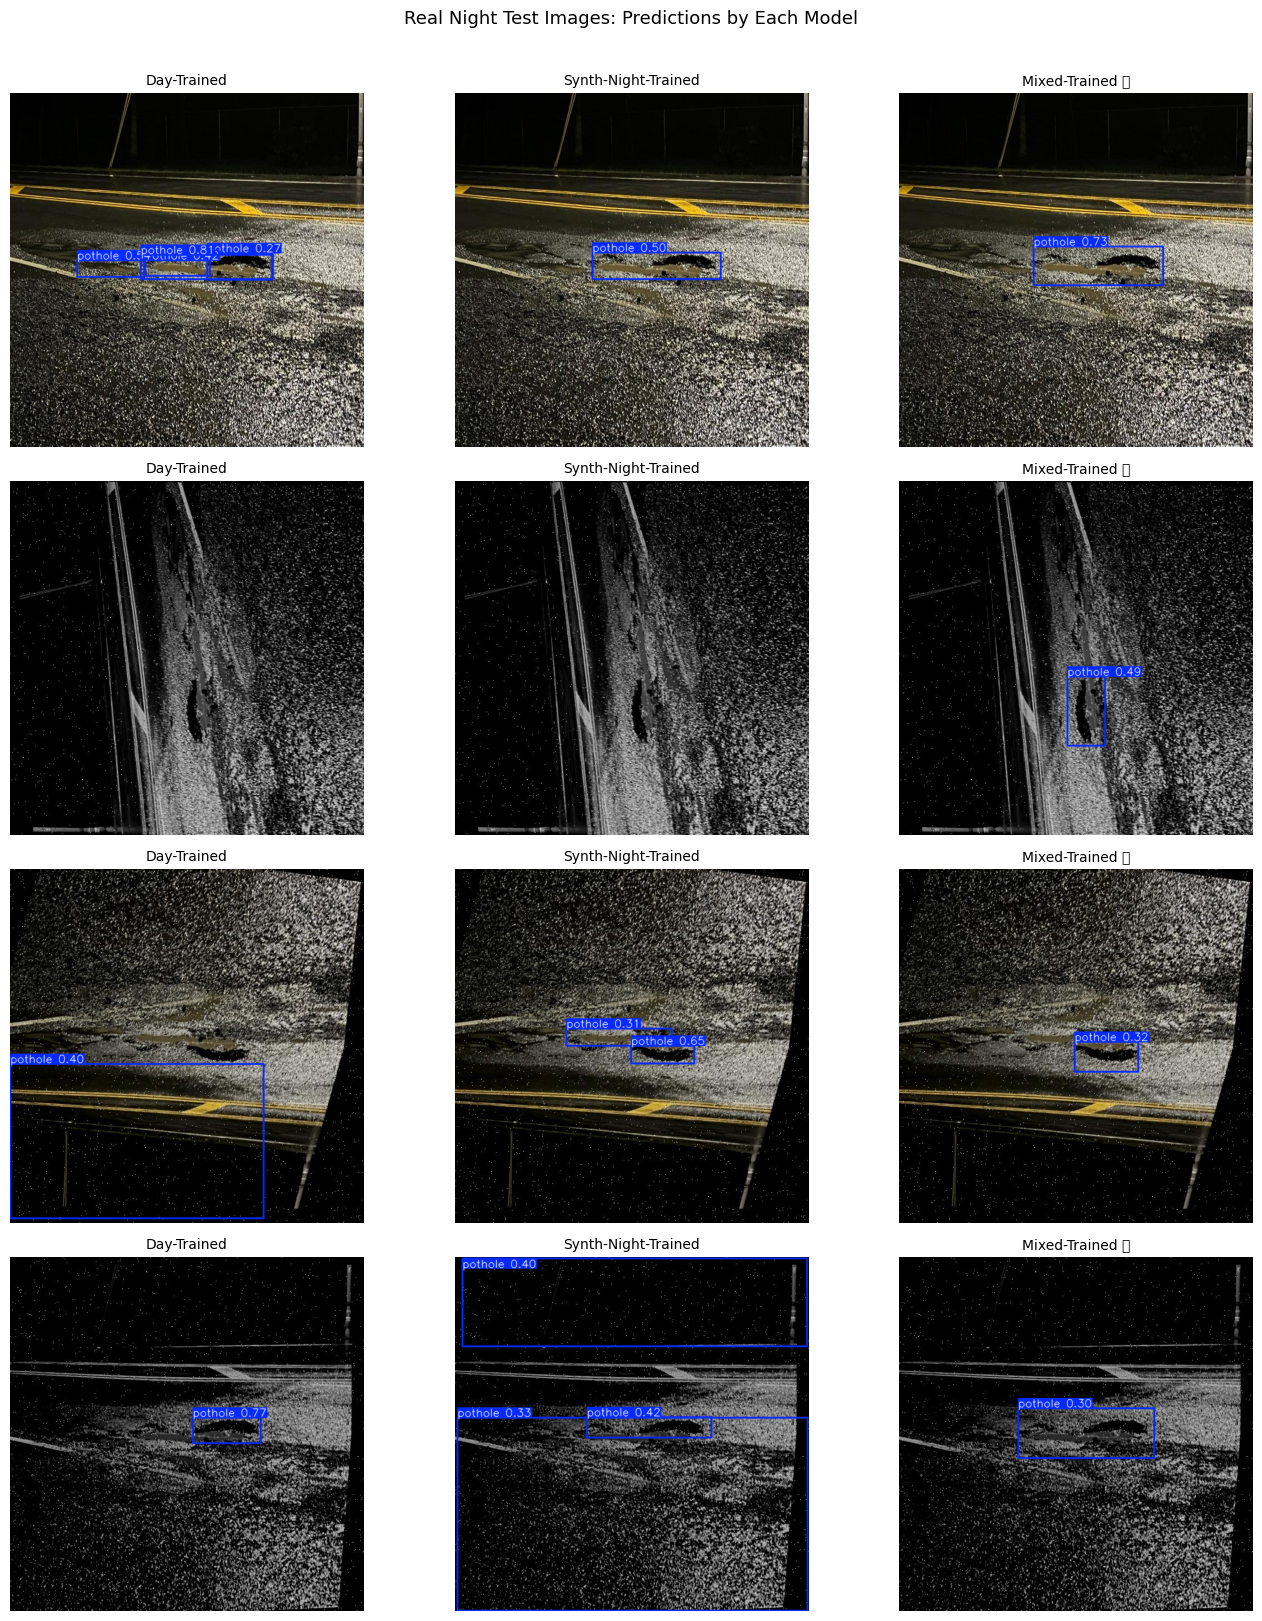

Saved to Drive: /content/drive/MyDrive/pothole_project/qualitative_comparison.png


In [12]:
# Cell 12: Visualize — 4 Real Night test images with predictions from each model
import matplotlib.pyplot as plt
import glob

sample_imgs = sorted(glob.glob('/content/Real_Night_Test_Only/images/test/*.jpg'))[:4]
models_to_show = [
    ('Day-Trained',           str(day_wts)),
    ('Synth-Night-Trained',   str(synth_wts)),
    ('Mixed-Trained ⭐',      str(mixed_wts)),
]

fig, axes = plt.subplots(len(sample_imgs), len(models_to_show), figsize=(14, 4*len(sample_imgs)))

for col, (model_name, wts_path) in enumerate(models_to_show):
    m = YOLO(wts_path)
    for row, img_path in enumerate(sample_imgs):
        preds = m.predict(img_path, conf=0.25, imgsz=640, verbose=False)
        plotted = preds[0].plot()
        ax = axes[row][col]
        ax.imshow(cv2.cvtColor(plotted, cv2.COLOR_BGR2RGB))
        ax.set_title(model_name, fontsize=10)
        ax.axis('off')

plt.suptitle('Real Night Test Images: Predictions by Each Model', fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig(str(DRIVE/'qualitative_comparison.png'), dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved to Drive: {DRIVE}/qualitative_comparison.png')

In [13]:
# Cell 13: Save Mixed Dataset ZIP to Google Drive
import shutil

zip_path = str(DRIVE / 'Mixed_SynthReal_Night')
print('Zipping Mixed dataset to Google Drive...')
shutil.make_archive(zip_path, 'zip', '/content/Mixed_SynthReal_Night')
print(f'Saved: {zip_path}.zip')
print(f'All model weights saved in: {RUNS}')
print('Done! All results are safely stored in Google Drive.')

Zipping Mixed dataset to Google Drive...
Saved: /content/drive/MyDrive/pothole_project/Mixed_SynthReal_Night.zip
All model weights saved in: /content/drive/MyDrive/pothole_project/runs
Done! All results are safely stored in Google Drive.
